## Contenido
1. Definición del problema
2. Limpieza y preprocesamiento
3. Análisis exploratorio
4. Segmentación de clientes (RFM)
5. Conclusiones finales

#1. Análisis de ventas y comportamiento de clientes de una tienda online

**Dataset:** Online Retail II (Kaggle / UCI), transacciones de dic-2009 a dic-2011.

**Preguntas que busco responder:**
1. ¿Cómo evolucionó la facturación mes a mes y hay estacionalidad?
2. ¿Qué productos y países generan más ingresos?
3. ¿Quiénes son los mejores clientes y cuánto concentran?
4. ¿Cuántos clientes vuelven a comprar?

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')

ruta = '/content/drive/MyDrive/proyecto-retail/merged_dataset_retail_2009_2011.csv'
df = pd.read_csv(ruta)

print(df.shape)
df.head()

Mounted at /content/drive
(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,12/1/09 7:45,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,12/1/09 7:45,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,12/1/09 7:45,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,12/1/09 7:45,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,12/1/09 7:45,1.25,13085.0,United Kingdom


#2. Limpieza y preprocesamiento

**En esta etapa buscamos dejar el dataset limpio, libre de datos mal ingresados, datos repetidos, valores nulos, errores de tipo de datos entre otros. Se realizaran en orden los siguientes procesos:**


  1.Estructura: cuántas filas y columnas hay, y qué significa cada columna.

  2.Tipos de datos: Errores en tipos de datos

  3.Valores faltantes (nulos): cuántos hay, en qué columnas y por qué (vemos que hacemos con esas columnas)

  4.Duplicados: filas repetidas

  5.Inconsistencias en texto: mayúsculas y minúsculas, espacios de más, errores de escritura, categorías repetidas con distinto nombre.

  6.Valores imposibles o ilógicos: precios negativos, edades de 200 años, fechas futuras.

  7.Valores atípicos (outliers): valores extremos que pueden ser errores o casos reales. Se investigan y luego vemos que hacer

  8.Consistencia entre columnas: que los datos tengan sentido entre sí.

**Estructura y tipos de columnas:**


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  object 
 1   StockCode    1067371 non-null  object 
 2   Description  1062989 non-null  object 
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 65.1+ MB


**Valores faltantes:**

In [ ]:
faltantes = df.isna().sum()
porcentaje = (df.isna().mean() * 100).round(2)
pd.DataFrame({'faltantes': faltantes, 'porcentaje': porcentaje})

,faltantes,porcentaje
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00


**Duplicados y valores raros:**

In [ ]:
print('Filas duplicadas:', df.duplicated().sum())
print('Cantidad <= 0:', (df['Quantity'] <= 0).sum())
print('Precio <= 0:', (df['Price'] <= 0).sum())
print('Facturas canceladas:', df['Invoice'].astype(str).str.startswith('C').sum())

Filas duplicadas: 34335
Cantidad <= 0: 22950
Precio <= 0: 6207
Facturas canceladas: 19494


**Resumen numérico:**

In [ ]:
df[['Quantity', 'Price']].describe()

,Quantity,Price
count,1.067371e+06,1.067371e+06
mean,9.938898e+00,4.649388e+00
std,1.727058e+02,1.235531e+02
min,-8.099500e+04,-5.359436e+04
25%,1.000000e+00,1.250000e+00
50%,3.000000e+00,2.100000e+00
75%,1.000000e+01,4.150000e+00
max,8.099500e+04,3.897000e+04


##Preprocesamiento de datos
**Investigación de anomalías**

Buscamos entender qué son los valores raros detectados en el diagnóstico inicial antes de decidir que hacer con ellos.

- Tenemos filas con precios menores o iguales a 0: (¿ajustes contables, productos regalados, errores de carga?).
- Tenemos cantidades extremas (±80.995). Ver si corresponden a una venta y su cancelación.
- Ver si los precios muy altos corresponden a productos reales o a cargos que no son productos (envío, comisiones, ajustes).
- Vemos que relación hay entre las cantidades negativas y las facturas canceladas (Las comenzadas con "C").



**Convertir la fecha:**

In [ ]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='%m/%d/%y %H:%M')
print(df['InvoiceDate'].min(), df['InvoiceDate'].max())

2009-12-01 07:45:00 2011-12-09 12:50:00


**Filas con precio < = 0:**
Descripciones más frecuentes entre las filas con precio cero o negativo.

In [ ]:
df[df['Price'] <= 0]['Description'].value_counts(dropna=False).head(10)

,count
Description,
NaN,4382
check,162
?,92
damages,84
damaged,81
found,28
missing,27
sold as set on dotcom,20
Damaged,17


**Precios altos:**

In [ ]:
df.nlargest(5, 'Price')

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
748142,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098.0,United Kingdom
241824,C512770,M,Manual,-1,2010-06-17 16:52:00,25111.09,17399.0,United Kingdom
241827,512771,M,Manual,1,2010-06-17 16:53:00,25111.09,NaN,United Kingdom
320581,C520667,BANK CHARGES,Bank Charges,-1,2010-08-27 13:42:00,18910.69,NaN,United Kingdom
1050063,C580605,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:36:00,17836.46,NaN,United Kingdom


**las cantidades más extremas:**

In [ ]:
df.loc[df['Quantity'].abs().nlargest(6).index]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,13902.0,Denmark
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark


###Observaciones
  1. Las fechas estan bien, van del 1/12/2009 al 9/12/2011.

  2. Los precios en cero (o negativos) no son ventas. Casi todos tienen descripción nula (4.382) o notas internas del tipo check, damaged, missing, found, adjustment. Son ajustes de inventario: Se anotó mercadería rota, perdida o encontrada. No generan ingresos.

  3. Los códigos M (Manual), BANK CHARGES y AMAZONFEE son cargos y ajustes contables cargados como si fueran ventas. Por eso hay un “precio” de 38.970.

  4. Las cantidades extremas son errores que se cancelaron. El pedido de 80.995 unidades (9:15) y la cancelación de -80.995 (9:27) son del mismo cliente, el mismo producto y están separados por 12 minutos: alguien se equivocó al cargar el pedido y lo canceló. Pasa lo mismo con 74.215 unidades. En cambio, las 19.152 y 12.960 unidades a Dinamarca (precio 0,10) no tienen cancelación: pueden ser compras mayoristas reales, así que se conservan pero se marcan como atípicas.

#Posibles decisiones a tomar

  1. Excluir del análisis de ventas los códigos que no son productos (M, BANK CHARGES, AMAZONFEE, etc.). No son ventas no sirven para analizar.

  2. Excluir las filas con precio <= 0 (ajustes de inventario). No representan ventas sino mercaderia rota, perdida, encontrada.

  3. Medir ingresos netos (ventas menos devoluciones y cancelaciones), de modo que los pares venta-cancelación se compensen solos.

  4. Conservar y marcar las compras grandes sin cancelación. (No tenemos suficiente informacion como para descartarlos, ni devoluciones al mismo usuario, ni nada. Lo conservamos)

**Codigos que no pertenecen a productos (los productos empiezan con 5 dígitos):**

In [ ]:
no_producto = df[~df['StockCode'].astype(str).str.match(r'^\d{5}')]
no_producto['StockCode'].value_counts().head(20)

,count
StockCode,


**Cantidades negativas (ver si están todas en facturas canceladas ("C")):**

In [ ]:
# 2) Cantidades negativas: ¿están todas en facturas canceladas ("C")?
neg = df[df['Quantity'] < 0]
es_cancel = neg['Invoice'].astype(str).str.startswith('C')
print('Negativas en facturas C:', es_cancel.sum())
print('Negativas sin C:', (~es_cancel).sum())

Negativas en facturas C: 17914
Negativas sin C: 0


**Filas con precio <= 0 (ver si tienen cliente asociado)**

In [ ]:
cero = df[df['Price'] <= 0]
print('Con Customer ID:', cero['Customer ID'].notna().sum(), 'de', len(cero))

Con Customer ID: 0 de 0


**Vemos si las negativas sin "C" Son ajustes de inventario:**

In [ ]:
neg_sin_c = df[(df['Quantity'] < 0) & (~df['Invoice'].astype(str).str.startswith('C'))]
print('Total:', len(neg_sin_c))
print('Con precio 0:', (neg_sin_c['Price'] == 0).sum())
print('Sin Customer ID:', neg_sin_c['Customer ID'].isna().sum())

Total: 0
Con precio 0: 0
Sin Customer ID: 0


**Descripciones de los códigos que no son productos**

In [ ]:
codigos = ['POST', 'DOT', 'M', 'C2', 'D', 'S', 'ADJUST', 'CRUK', 'PADS', 'TEST001']
df[df['StockCode'].isin(codigos)].groupby('StockCode')['Description'].agg(lambda x: x.mode().iloc[0])

,Description
StockCode,


**El patrón del cliente de Dinamarca:**

In [ ]:
df[df['Customer ID'] == 13902.0].nlargest(10, 'Quantity')[['Invoice', 'Description', 'Quantity', 'Price', 'InvoiceDate']]

,Invoice,Description,Quantity,Price,InvoiceDate
90857,497946,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,2010-02-15 11:57:00
127166,501534,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,2010-03-17 13:09:00
127168,501534,SET/6 WOODLAND PAPER PLATES,12960,0.10,2010-03-17 13:09:00
127169,501534,SET/6 WOODLAND PAPER CUPS,12744,0.10,2010-03-17 13:09:00
127167,501534,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,2010-03-17 13:09:00
93677,498152,SMALL FAIRY CAKE FRIDGE MAGNETS,9456,0.30,2010-02-17 10:51:00
65091,495194,JAZZ HEARTS MEMO PAD,9312,0.10,2010-01-21 15:11:00
65090,495194,JAZZ HEARTS MAGNETIC MEMO PAD,6768,0.10,2010-01-21 15:11:00
90866,497946,ASS FLORAL PRINT SCISSORS,6696,0.15,2010-02-15 11:57:00
65079,495194,POP-ART FLUORESCENT PENS,6144,0.06,2010-01-21 15:11:00


**Confirmaciones:**

  1. Las 3.457 cantidades negativas sin “C” tienen todas precio 0 y ninguna tiene cliente. Son ajustes de inventario

  2. Los códigos no-producto quedan confirmados por sus descripciones: POST y DOT (envíos), C2 (transporte), D (descuentos), S (muestras), M y ADJUST (ajustes manuales), CRUK (comisión), TEST001 (producto de prueba).

  3. El cliente 13902 (Dinamarca) hizo varias compras grandes de productos baratos (vasos, platos de papel, memo pads) en facturas y fechas distintas, sin cancelaciones. Puede llegar a ser un mayorista, la conservamos pero la marcamos por no saber que es con certeza.

  4.

##Limpieza de datos

**Creamos un respaldo:**

In [ ]:
df_raw = df.copy()   # respaldo de los datos originales
n_inicial = len(df)

**Eliminamos duplicados exactos:**

In [ ]:
df = df.drop_duplicates()
print('Duplicados eliminados:', n_inicial - len(df))

Duplicados eliminados: 34335


**Separamos los códigos que no son productos (los productos reales empiezan con 5 dígitos):**

In [ ]:
es_producto = df['StockCode'].astype(str).str.match(r'^\d{5}')
df_no_producto = df[~es_producto]     # lo guardamos aparte, no se pierde
df = df[es_producto]
print('Filas no-producto separadas:', len(df_no_producto))

Filas no-producto separadas: 5980


**separar las filas con precio <= 0 (ajustes de inventario):**

In [ ]:
ajustes = df['Price'] <= 0
df_ajustes = df[ajustes]
df = df[~ajustes]
print('Filas con precio <= 0 separadas:', len(df_ajustes))

Filas con precio <= 0 separadas: 5928


##Transformacion de datos

**Columnas nuevas:**

In [ ]:
df['es_cancelacion'] = df['Invoice'].astype(str).str.startswith('C')
df['Revenue'] = df['Quantity'] * df['Price']          # negativo en cancelaciones
df['es_atipica'] = df['Quantity'].abs() >= 10000      # pedidos de volumen extremo (marcados, no eliminados)

**Verificacion:**

In [ ]:
print('Filas finales:', len(df))
print('Negativas sin cancelación:', ((df['Quantity'] < 0) & ~df['es_cancelacion']).sum())
print('Atípicas marcadas:', df['es_atipica'].sum())
print('Sin Customer ID:', df['Customer ID'].isna().sum())

Filas finales: 1021128
Negativas sin cancelación: 0
Atípicas marcadas: 13
Sin Customer ID: 226965


## Limpieza: decisiones y justificación

| Decisión | Filas afectadas | Justificación |
|---|---|---|
| Eliminar duplicados exactos | 34.335 | Filas repetidas inflarían ventas y cantidades |
| Separar códigos que no son productos (envíos, descuentos, ajustes, pruebas) | 5.980 | Son cargos administrativos, no ventas de productos |
| Separar filas con precio <= 0 | 5.928 | Ajustes de inventario sin cliente; no generan ingresos |
| Conservar cancelaciones y marcarlas (`es_cancelacion`) | 17.914 | Las devoluciones son información de negocio; permiten medir ingreso neto |
| Conservar filas sin Customer ID | 226.965 | Sirven para el análisis de ventas; se excluyen solo del análisis de clientes |
| Marcar pedidos de volumen extremo (`es_atipica`) | 13 | Pueden ser mayoristas reales; se analiza la sensibilidad con y sin ellos |

**Resultado:** 1.021.128 filas listas para el análisis.

**Guardamos el dataset limpio:**

In [ ]:
df.to_csv('/content/drive/MyDrive/proyecto-retail/retail_limpio.csv', index=False)

#3. Analisis exploratorio de datos

##Evolución de los ingresos por mes

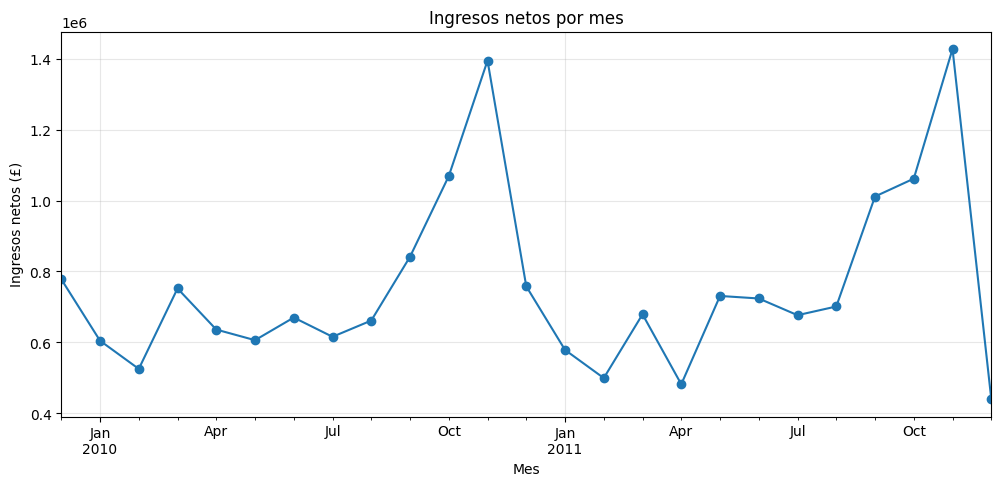

,Revenue
Mes,
2011-11-01,1427121.25
2010-11-01,1394454.49
2010-10-01,1068906.61
2011-10-01,1061697.93
2011-09-01,1011333.16


In [ ]:
df['Mes'] = df['InvoiceDate'].dt.to_period('M').dt.to_timestamp()
ventas_mes = df.groupby('Mes')['Revenue'].sum()

plt.figure(figsize=(12, 5))
ventas_mes.plot(marker='o')
plt.title('Ingresos netos por mes')
plt.xlabel('Mes')
plt.ylabel('Ingresos netos (£)')
plt.grid(alpha=0.3)
plt.show()

ventas_mes.sort_values(ascending=False).head(5)

**La caida de Diciembre es porque los datos llegan hasta ese mes**

**Hallazgo:** los ingresos muestran una fuerte estacionalidad, con un pico en noviembre
(más del doble de un mes típico) y los valores más bajos en enero y febrero.
Diciembre de 2011 aparece incompleto (datos hasta el 9/12), por lo que no es comparable.

##Productos y países que más ingresan


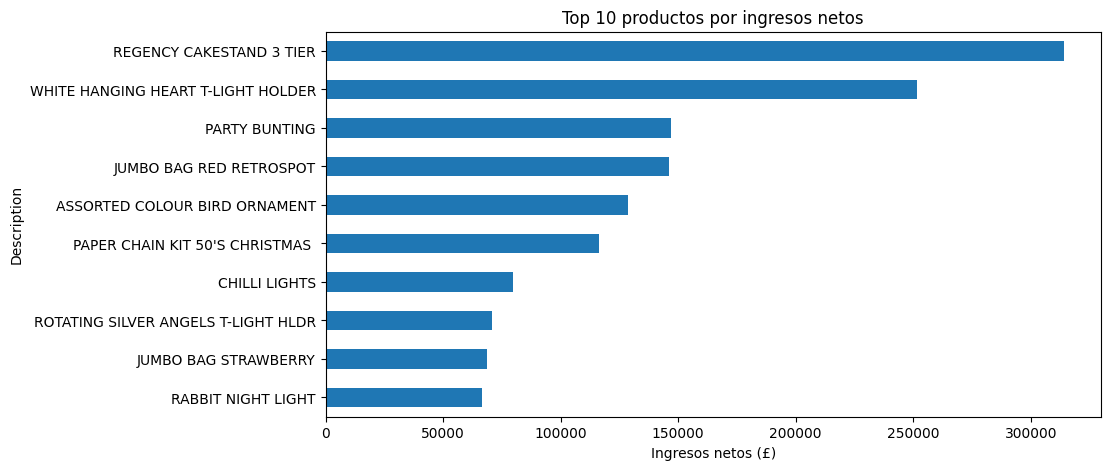

,Revenue
Description,
REGENCY CAKESTAND 3 TIER,314045.02
WHITE HANGING HEART T-LIGHT HOLDER,251603.12
PARTY BUNTING,147079.73
JUMBO BAG RED RETROSPOT,145946.05
ASSORTED COLOUR BIRD ORNAMENT,128550.42
PAPER CHAIN KIT 50'S CHRISTMAS,116298.59
CHILLI LIGHTS,79905.13
ROTATING SILVER ANGELS T-LIGHT HLDR,70969.95
JUMBO BAG STRAWBERRY,68489.89


In [ ]:
# Top 10 productos por ingresos netos
top_productos = df.groupby('Description')['Revenue'].sum().nlargest(10)
top_productos.sort_values().plot(kind='barh', figsize=(10, 5))
plt.title('Top 10 productos por ingresos netos')
plt.xlabel('Ingresos netos (£)')
plt.show()
top_productos

##Top 10 paises por ingresos netos


In [ ]:
ingresos_pais = df.groupby('Country')['Revenue'].sum().sort_values(ascending=False)
print('Participación de Reino Unido: {:.1%}'.format(ingresos_pais['United Kingdom'] / ingresos_pais.sum()))
ingresos_pais.head(10)

Participación de Reino Unido: 85.4%


,Revenue
Country,
United Kingdom,16167773.06
EIRE,603116.61
Netherlands,546095.43
Germany,374573.51
France,293431.20
Australia,166282.15
Switzerland,92918.06
Spain,84811.56
Sweden,84345.17


**Productos**
- Los ingresos están muy repartidos: los 10 productos principales suman unas £1,39 millones, alrededor del 7% de los ingresos netos totales (£18,9 millones). Ningún producto domina el negocio.
- Los dos productos con más ingresos son el *Regency Cakestand 3 Tier* (£314.000) y el *White Hanging Heart T-Light Holder* (£252.000).
- Varios productos del top 10 son de temática navideña (*Paper Chain Kit 50's Christmas*, *Chilli Lights*, *Rotating Silver Angels*), lo que es coherente con el pico de ventas de septiembre a noviembre. Sin embargo, otros productos principales no son navideños, por lo que la estacionalidad no se explica solo por ellos.

**Países**
- El negocio depende casi por completo del mercado británico: Reino Unido aporta £16,2 millones, cerca del 85% de los ingresos netos.
- Los siguientes países son Irlanda (EIRE), Países Bajos, Alemania y Francia, con montos mucho menores.
- Países Bajos ocupa el 3.er lugar con muchas menos filas de transacciones que Alemania o Francia, lo que sugiere pedidos de mayor tamaño (hipótesis a verificar en el análisis de clientes).

**Nota metodológica:** los ingresos son netos (ventas menos devoluciones y cancelaciones) y excluyen envíos y cargos administrativos, que se separaron en la limpieza.

##Mejores clientes y cuánto concentran

In [ ]:
clientes = df[df['Customer ID'].notna()]
ingresos_cliente = clientes.groupby('Customer ID')['Revenue'].sum().sort_values(ascending=False)

print('Clientes identificados:', len(ingresos_cliente))
n_top = int(len(ingresos_cliente) * 0.2)
print('El 20% de clientes con más compras concentra: {:.1%}'.format(
    ingresos_cliente.head(n_top).sum() / ingresos_cliente.sum()))
print('Los 10 mejores clientes concentran: {:.1%}'.format(
    ingresos_cliente.head(10).sum() / ingresos_cliente.sum()))
ingresos_cliente.head(10)

Clientes identificados: 5875
El 20% de clientes con más compras concentra: 76.9%
Los 10 mejores clientes concentran: 16.3%


,Revenue
Customer ID,
18102.0,578408.64
14646.0,523202.74
14156.0,297775.01
14911.0,258522.43
17450.0,233643.91
13694.0,190391.50
17511.0,168504.44
12415.0,143107.02
16684.0,141530.29


**Hallazgos:**

- Se identificaron 5.875 clientes. El 20% con más compras (unos 1.175 clientes) concentra el 76,9% de los ingresos netos, un valor cercano a la regla de Pareto (80/20).
- No hay dependencia de un único cliente: los 10 mejores clientes concentran el 16,3% de los ingresos y el mejor (ID 18102, £578.408) aporta alrededor del 3,5%.
- Implicancia de negocio: conviene cuidar y fidelizar a ese grupo reducido de clientes de alto valor, que sostiene la mayor parte de la facturación.

**Limitación:** el análisis considera solo las ventas con Customer ID (aprox. 78% de las filas); las ventas sin cliente asociado no se pueden atribuir a ningún cliente.

##Recompra de cliente

In [ ]:
ventas = df[df['Customer ID'].notna() & ~df['es_cancelacion']]
facturas_por_cliente = ventas.groupby('Customer ID')['Invoice'].nunique()

print('Clientes que compraron más de una vez: {:.1%}'.format((facturas_por_cliente > 1).mean()))
facturas_por_cliente.describe()

Clientes que compraron más de una vez: 72.4%


,Invoice
count,5852.000000
mean,6.253247
std,12.749286
min,1.000000
25%,1.000000
50%,3.000000
75%,7.000000
max,373.000000


##Hipótesis de Países Bajos

In [ ]:
paises = ['United Kingdom', 'EIRE', 'Netherlands', 'Germany', 'France']
tabla = (df[df['Customer ID'].notna() & df['Country'].isin(paises)]
         .groupby('Country')
         .agg(clientes=('Customer ID', 'nunique'), ingresos=('Revenue', 'sum')))
tabla['ingreso_por_cliente'] = (tabla['ingresos'] / tabla['clientes']).round(0)
tabla.sort_values('ingresos', ascending=False)

,clientes,ingresos,ingreso_por_cliente
Country,,,
United Kingdom,5357,13660973.69,2550.0
EIRE,3,567577.15,189192.0
Netherlands,22,546095.43,24823.0
Germany,107,374573.51,3501.0
France,93,291744.07,3137.0


**Hallazgos:**

- Recompra: el 72,4% de los clientes identificados compró más de una vez. La mediana es de 3 facturas por cliente; el promedio (6,25) está inflado por unos pocos clientes muy frecuentes (máximo: 373 facturas).
- Se confirma la hipótesis sobre Países Bajos: tiene solo 22 clientes, pero cada uno aporta en promedio £24.823, unas 10 veces más que un cliente británico (£2.550), lo que sugiere un perfil mayorista.
- Irlanda (EIRE) factura £567.577 con solo 3 clientes: su ingreso depende de muy pocos compradores.
- Implicancia de negocio: la mayor parte de los clientes vuelve a comprar, pero algunos mercados internacionales dependen de unos pocos compradores muy grandes, lo que implica riesgo de concentración.

**Limitaciones:** los clientes con una sola compra incluyen clientes recientes que aún no tuvieron oportunidad de recomprar; el análisis excluye las ventas sin Customer ID.

## Sensibilidad frente a pedidos atípicos

In [ ]:
sin_atipicas = df[~df['es_atipica']]
total_con = df['Revenue'].sum()
total_sin = sin_atipicas['Revenue'].sum()

print('Ingresos netos con atípicas: £{:,.0f}'.format(total_con))
print('Ingresos netos sin atípicas: £{:,.0f}'.format(total_sin))
print('Diferencia: {:.2%}'.format(1 - total_sin / total_con))

Ingresos netos con atípicas: £18,926,266
Ingresos netos sin atípicas: £18,909,237
Diferencia: 0.09%


**Hallazgos: sensibilidad frente a pedidos atípicos**

- Se marcaron 13 pedidos de volumen extremo (10.000 unidades o más). Al excluirlos, los ingresos netos pasan de £18.926.266 a £18.909.237, una diferencia de 0,09%.
- Los pedidos erróneos (80.995 y 74.215 unidades, cancelados minutos después) se compensan en el ingreso neto. Los restantes son grandes en unidades pero de bajo valor unitario (£0,10 a £0,25), por lo que su impacto en dinero es mínimo.
- Conclusión: los resultados del análisis son robustos frente a estos pedidos y se conservan en el dataset.

#4. Segmentación de clientes (RFM)
  Recency (R): hace cuántos días compró por última vez. Cuanto menos, mejor.

  Frequency (F): cuántas veces compró.

  Monetary (M): cuánto dinero dejó en total.

##Tabla RFM

In [ ]:
# Excluimos los 4 registros de los pedidos erróneos (venta y cancelación a los pocos minutos)
errores = ['581483', 'C581484', '541431', 'C541433']
clientes = df[df['Customer ID'].notna() & ~df['Invoice'].astype(str).isin(errores)]

# Fecha de referencia: un día después de la última venta del dataset
fecha_ref = clientes['InvoiceDate'].max() + pd.Timedelta(days=1)

# R y F se calculan solo con compras efectivas (sin cancelaciones)
ventas = clientes[~clientes['es_cancelacion']]
rfm = ventas.groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda x: (fecha_ref - x.max()).days),
    Frequency=('Invoice', 'nunique'))

# M es el ingreso neto (ventas menos devoluciones)
rfm['Monetary'] = clientes.groupby('Customer ID')['Revenue'].sum()

# Quitamos clientes cuyo neto es cero o negativo (devolvieron más de lo que compraron)
rfm = rfm[rfm['Monetary'] > 0]

print(len(rfm))
rfm.describe().round(1)

5838


,Recency,Frequency,Monetary
count,5838.0,5838.0,5838.0
mean,200.0,6.3,2802.6
std,208.4,12.8,13841.1
min,1.0,1.0,0.0
25%,25.0,1.0,332.7
50%,95.0,3.0,842.4
75%,379.0,7.0,2173.6
max,738.0,373.0,578408.6


##Puntajes y segmentos

In [ ]:
# Puntajes de 1 (peor) a 4 (mejor). En Recency, menos días es mejor, por eso se invierten las etiquetas.
rfm['R'] = pd.qcut(rfm['Recency'], 4, labels=[4, 3, 2, 1]).astype(int)
rfm['F'] = pd.qcut(rfm['Frequency'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
rfm['M'] = pd.qcut(rfm['Monetary'], 4, labels=[1, 2, 3, 4]).astype(int)

def segmentar(fila):
    if fila['R'] >= 3 and fila['F'] >= 3 and fila['M'] >= 3:
        return 'Campeones'
    if fila['R'] >= 3 and fila['F'] >= 2:
        return 'Clientes leales'
    if fila['R'] >= 3 and fila['F'] <= 1:
        return 'Recientes (poca frecuencia)'
    if fila['R'] <= 2 and fila['F'] >= 3:
        return 'En riesgo'
    return 'Dormidos / perdidos'

rfm['Segmento'] = rfm.apply(segmentar, axis=1)

resumen = rfm.groupby('Segmento').agg(
    clientes=('R', 'size'),
    recency_mediana=('Recency', 'median'),
    frecuencia_mediana=('Frequency', 'median'),
    ingresos=('Monetary', 'sum'))
resumen['% clientes'] = (resumen['clientes'] / len(rfm) * 100).round(1)
resumen['% ingresos'] = (resumen['ingresos'] / rfm['Monetary'].sum() * 100).round(1)
resumen.sort_values('% ingresos', ascending=False)

,clientes,recency_mediana,frecuencia_mediana,ingresos,% clientes,% ingresos
Segmento,,,,,,
Campeones,1803,22.0,9.0,12611488.80,30.9,77.1
En riesgo,881,243.0,5.0,2006662.17,15.1,12.3
Dormidos / perdidos,2033,407.0,1.0,1036022.70,34.8,6.3
Clientes leales,787,30.0,3.0,580299.54,13.5,3.5
Recientes (poca frecuencia),334,46.0,1.0,127096.92,5.7,0.8


**Hallazgos de la segmentación RFM**

- Los Campeones son el 30,9% de los clientes y generan el 77,1% de los ingresos netos: es el grupo más importante y el que más conviene proteger.
- El segmento En riesgo (15,1% de los clientes, 12,3% de los ingresos) estaba formado por clientes que compraban con frecuencia (mediana: 5 compras) pero llevan unos 8 meses sin volver (mediana: 243 días). Es el grupo con mayor potencial de reactivación.
- Los Dormidos / perdidos son el 34,8% de los clientes pero solo el 6,3% de los ingresos, por lo que no justifican una inversión alta.

**Acciones sugeridas:** atención personalizada para Campeones; campañas de reactivación para En riesgo, idealmente antes del pico de temporada (agosto), con contacto directo y descuentos por volumen si se confirma un perfil mayorista; campañas de bajo costo para Dormidos.

**Limitaciones:** no se dispone de datos de margen ni de costos, por lo que no se puede estimar la rentabilidad de las campañas; los segmentos se definieron con reglas simples sobre cuartiles, que pueden ajustarse.

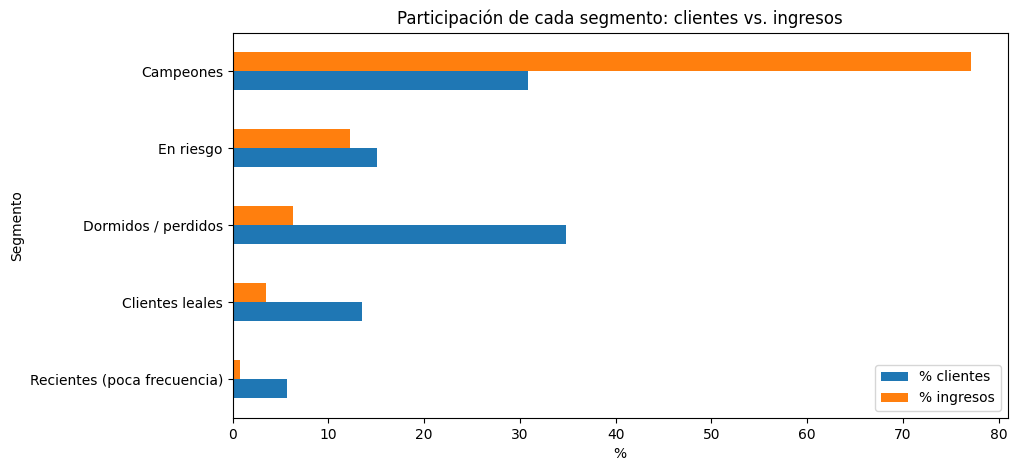

In [ ]:
resumen[['% clientes', '% ingresos']].sort_values('% ingresos').plot(kind='barh', figsize=(10, 5))
plt.title('Participación de cada segmento: clientes vs. ingresos')
plt.xlabel('%')
plt.show()

#5. Consusiones finales

**Ventas**
- Hay una estacionalidad marcada: el pico va de septiembre a noviembre, y noviembre (unos £1,4 millones) es más del doble de un mes típico. Enero y febrero son los meses más bajos.
- El crecimiento entre 2010 y 2011 es modesto (noviembre de 2011 fue solo un 2% mayor que el de 2010).
- Los ingresos están muy repartidos entre productos (el top 10 suma cerca del 7%) y muy concentrados en un país: Reino Unido aporta cerca del 85%.

**Clientes**
- El 20% de los clientes concentra el 76,9% de los ingresos, pero ningún cliente individual domina (el mejor aporta cerca del 3,5%).
- El 72,4% de los clientes compró más de una vez.
- Algunos mercados dependen de pocos compradores: Países Bajos (22 clientes, unos £24.800 por cliente) e Irlanda (3 clientes, £567.000 en total).

**Segmentación RFM**
- Los Campeones son el 30,9% de los clientes y generan el 77,1% de los ingresos.
- El segmento En riesgo (15,1% de los clientes, 12,3% de los ingresos) es el de mayor potencial de reactivación.

**Recomendaciones**
- Proteger a los Campeones con atención personalizada.
- Lanzar campañas de reactivación para En riesgo antes del pico de temporada (por ejemplo, en agosto).
- Evaluar descuentos por volumen si se confirma un perfil mayorista.

**Limitaciones**
- No hay datos de márgenes ni costos, por lo que no se puede estimar la rentabilidad de las acciones.
- Cerca del 22% de las filas no tienen Customer ID y quedan fuera del análisis de clientes.
- El dataset cubre 2009-2011 y diciembre de 2011 está incompleto.
- El perfil mayorista es una hipótesis que sugieren los datos, pero no está confirmada.

**Próximos pasos posibles:** segmentar con KMeans, hacer un pronóstico de ventas y armar un dashboard interactivo.